In [1]:
import pandas as pd
import matplotlib.pyplot as plt

print("Powering the Planet project started!")
print("Pandas version:", pd.__version__)

Matplotlib is building the font cache; this may take a moment.


Powering the Planet project started!
Pandas version: 2.3.3


# Powering the Planet: Energy, Economic Growth and CO₂ Emissions

## Project overview

This project investigates the relationship between economic growth, energy consumption and carbon dioxide emissions across seven countries: Italy, Germany, the United Kingdom, the United States, China, India and Brazil.

## Research question

Can countries grow their economies while reducing CO₂ emissions per capita, and how has their energy mix changed since 1990?

## Data sources

- Our World in Data — Energy dataset
- Our World in Data — CO₂ emissions dataset

## Methodology

The analysis uses Python, pandas and Matplotlib to load and clean data, compare countries, calculate percentage changes and visualize trends in energy sources and CO₂ emissions.

## Limitations

The economic comparison uses the available observations through 2022. GDP per capita and CO₂ per capita are used to compare trends; the results show associations rather than proving causation. Production-based emissions also exclude emissions embodied in imported products.

In [1]:
from data_loader import load_energy_data, load_co2_data
from analysis import COUNTRIES, filter_countries, calculate_decoupling
from visualizations import plot_co2_trends

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Project folders
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

# Load datasets through our reusable module
energy = load_energy_data()
co2 = load_co2_data()

# Prepare country-level datasets
energy_clean = filter_countries(energy)
co2_clean = filter_countries(co2)

# Keep a familiar variable name for the existing CO2 chart
df = co2_clean.copy()

print("Project modules connected successfully!")
print("Energy dataset:", energy.shape)
print("CO2 dataset:", co2.shape)
print("Countries:", COUNTRIES)

Project modules connected successfully!
Energy dataset: (23377, 130)
CO2 dataset: (50411, 79)
Countries: ['Italy', 'Germany', 'United Kingdom', 'United States', 'China', 'India', 'Brazil']


In [2]:
# Calculate GDP per capita and CO2 per capita changes
summary = calculate_decoupling(energy, co2)

# Classify each country's trend
summary["Finding"] = summary.apply(
    lambda row: (
        "Relative decoupling"
        if row["GDP per capita change (%)"] > 0
        and row["CO2 per capita change (%)"] < 0
        else "Growth with rising emissions"
        if row["GDP per capita change (%)"] > 0
        and row["CO2 per capita change (%)"] > 0
        else "Other trend"
    ),
    axis=1
)

display(summary)

,Country,Start year,End year,GDP per capita change (%),CO2 per capita change (%),Finding
0,Brazil,1990,2022,90.68,55.70,Growth with rising emissions
1,China,1990,2022,544.80,281.71,Growth with rising emissions
2,Germany,1990,2022,83.87,-39.98,Relative decoupling
3,India,1990,2022,263.06,197.24,Growth with rising emissions
4,Italy,1990,2022,38.48,-25.75,Relative decoupling
5,United Kingdom,1990,2022,46.15,-56.51,Relative decoupling
6,United States,1990,2022,56.33,-26.92,Relative decoupling


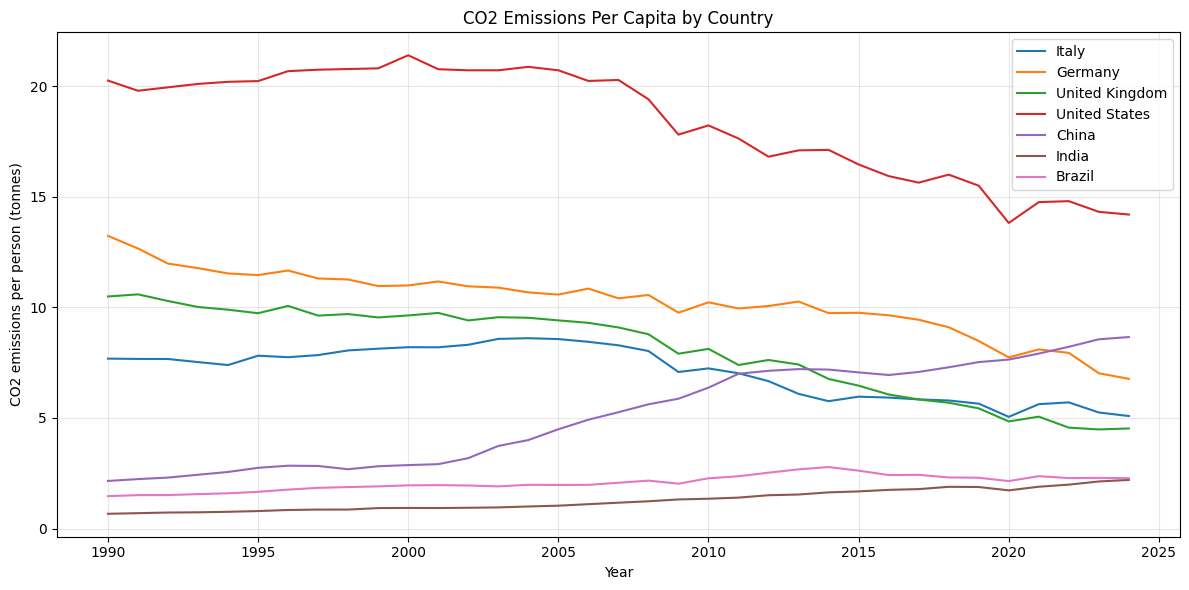

In [3]:
fig = plot_co2_trends(
    data=co2_clean,
    countries=COUNTRIES,
    output_path=OUTPUT_DIR / "co2_emissions_per_capita.png"
)

plt.show()

In [4]:
summary.to_csv(
    OUTPUT_DIR / "decoupling_results.csv",
    index=False
)

print("Decoupling results saved successfully!")

Decoupling results saved successfully!


In [5]:
summary = calculate_decoupling(energy, co2)

display(summary)

,Country,Start year,End year,GDP per capita change (%),CO2 per capita change (%)
0,Brazil,1990,2022,90.68,55.70
1,China,1990,2022,544.80,281.71
2,Germany,1990,2022,83.87,-39.98
3,India,1990,2022,263.06,197.24
4,Italy,1990,2022,38.48,-25.75
5,United Kingdom,1990,2022,46.15,-56.51
6,United States,1990,2022,56.33,-26.92


In [2]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())

Current folder:
/Users/swayamdoshi

Files in this folder:
['.Rhistory', '.config', 'Music', 'myDocuments.cannedSearch', '.DS_Store', 'Powering_the_Planet.ipynb', '.vscode-shared', '.CFUserTextEncoding', '.packettracer', '.local', '.mongodb', 'Pictures', '.zprofile', '.zsh_history', '.ipython', 'Desktop', 'Library', 'html', '.matplotlib', 'Sites', 'Public', '.diffusionbee', '.RData', 'Movies', 'Applications', '.profile', '.Rapp.history', '.Trash', '.ipynb_checkpoints', '.npm', '.homebrew', 'Documents', '.claude.json', '.vscode', '.bash_profile', 'Downloads', '.bash_history', '.zprofile.save', '.zsh_sessions']


In [3]:
import os

project_folder = os.path.expanduser(
    "~/Downloads/Powering_the_Planet"
)

os.makedirs(project_folder, exist_ok=True)

print("Project folder created at:")
print(project_folder)


Project folder created at:
/Users/swayamdoshi/Downloads/Powering_the_Planet


In [4]:
import os

print("Files in Downloads:")
print(os.listdir(os.path.expanduser("~/Downloads")))

Files in Downloads:
['~$P Letter.pdf', '.DS_Store', 'coding & data', '~$rtificate mini-anusha.docx', '.localized', '~$L Reportskin care.docx', 'microsoft', 'projects', 'entertainment', '~$ya_pharmacology-II.docx', 'kit', 'Powering_the_Planet', 'statistical Theory & mathematics', 'youtube', '~$armacology CG CIE II.docx']


In [5]:
import shutil
import os

downloads = os.path.expanduser("~/Downloads")
project_folder = os.path.join(
    downloads, "Powering_the_Planet"
)

for filename in [
    "owid-energy-data.csv",
    "owid-co2-data.csv"
]:
    source = os.path.join(downloads, filename)
    destination = os.path.join(project_folder, filename)

    if os.path.exists(source):
        shutil.move(source, destination)
        print("Moved:", filename)
    elif os.path.exists(destination):
        print("Already in project folder:", filename)
    else:
        print("NOT FOUND:", filename)

print("\nProject files:")
print(os.listdir(project_folder))

Already in project folder: owid-energy-data.csv
Already in project folder: owid-co2-data.csv

Project files:
['owid-co2-data.csv', 'owid-energy-data.csv']


In [6]:
import pandas as pd
import os

project_folder = os.path.expanduser(
    "~/Downloads/Powering_the_Planet"
)

energy = pd.read_csv(
    os.path.join(project_folder, "owid-energy-data.csv")
)

co2 = pd.read_csv(
    os.path.join(project_folder, "owid-co2-data.csv")
)

print("Energy dataset:", energy.shape)
print("CO2 dataset:", co2.shape)

print("\nEnergy preview:")
display(energy.head())

print("\nCO2 preview:")
display(co2.head())

Energy dataset: (23377, 130)
CO2 dataset: (50411, 79)

Energy preview:


,country,year,iso_code,population,gdp,biofuel_cons_change_pct,biofuel_cons_change_twh,biofuel_cons_per_capita,biofuel_consumption,biofuel_elec_per_capita,...,solar_share_elec,solar_share_energy,wind_cons_change_pct,wind_cons_change_twh,wind_consumption,wind_elec_per_capita,wind_electricity,wind_energy_per_capita,wind_share_elec,wind_share_energy
0,ASEAN (Ember),2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
3,ASEAN (Ember),2003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
4,ASEAN (Ember),2004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN



CO2 preview:


,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,...,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
0,Afghanistan,1750,AFG,2802560.0,NaN,0.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,1751,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# Countries selected for our project
countries = [
    "Italy",
    "Germany",
    "United Kingdom",
    "United States",
    "China",
    "India",
    "Brazil"
]

# Keep only our selected countries and years from 1990 onward
energy_clean = energy[
    (energy["country"].isin(countries)) &
    (energy["year"] >= 1990)
].copy()

co2_clean = co2[
    (co2["country"].isin(countries)) &
    (co2["year"] >= 1990)
].copy()

print("Energy dataset after filtering:", energy_clean.shape)
print("CO2 dataset after filtering:", co2_clean.shape)

print("\nCountries in energy dataset:")
print(sorted(energy_clean["country"].unique()))

print("\nCountries in CO2 dataset:")
print(sorted(co2_clean["country"].unique()))

Energy dataset after filtering: (252, 130)
CO2 dataset after filtering: (245, 79)

Countries in energy dataset:
['Brazil', 'China', 'Germany', 'India', 'Italy', 'United Kingdom', 'United States']

Countries in CO2 dataset:
['Brazil', 'China', 'Germany', 'India', 'Italy', 'United Kingdom', 'United States']


In [8]:
# Check the columns required for our analysis
columns_to_check = [
    "country",
    "year",
    "population",
    "gdp",
    "co2",
    "co2_per_capita",
    "coal_share_energy",
    "oil_share_energy",
    "gas_share_energy",
    "nuclear_share_energy",
    "renewables_share_energy"
]

for column in columns_to_check:
    print(
        column,
        "->",
        "Available" if (
            column in energy_clean.columns
            or column in co2_clean.columns
        ) else "Not available"
    )

country -> Available
year -> Available
population -> Available
gdp -> Available
co2 -> Available
co2_per_capita -> Available
coal_share_energy -> Available
oil_share_energy -> Available
gas_share_energy -> Available
nuclear_share_energy -> Available
renewables_share_energy -> Available


In [9]:
print("Energy data year range:")
print(
    energy_clean.groupby("country")["year"]
    .agg(["min", "max"])
)

print("\nCO2 data year range:")
print(
    co2_clean.groupby("country")["year"]
    .agg(["min", "max"])
)

Energy data year range:
                 min   max
country                   
Brazil          1990  2025
China           1990  2025
Germany         1990  2025
India           1990  2025
Italy           1990  2025
United Kingdom  1990  2025
United States   1990  2025

CO2 data year range:
                 min   max
country                   
Brazil          1990  2024
China           1990  2024
Germany         1990  2024
India           1990  2024
Italy           1990  2024
United Kingdom  1990  2024
United States   1990  2024


In [10]:
# Select the columns we need from the CO2 dataset
co2_selected = co2_clean[
    ["country", "year", "co2_per_capita"]
].copy()

# Merge energy and CO2 data by country and year
df = pd.merge(
    energy_clean,
    co2_selected,
    on=["country", "year"],
    how="inner",
    suffixes=("_energy", "_co2")
)

# Keep the main comparison period consistent
df = df[
    (df["year"] >= 1990) &
    (df["year"] <= 2024)
].copy()

# Sort the data
df = df.sort_values(["country", "year"])

print("Merged dataset shape:", df.shape)

display(
    df[[
        "country",
        "year",
        "population",
        "gdp",
        "co2_per_capita"
    ]].head(10)
)

Merged dataset shape: (245, 131)


,country,year,population,gdp,co2_per_capita
0,Brazil,1990,149143223.0,1.185475e+12,1.466092
1,Brazil,1991,151724253.0,1.213090e+12,1.511911
2,Brazil,1992,154275077.0,1.221829e+12,1.514184
3,Brazil,1993,156794574.0,1.298221e+12,1.558125
4,Brazil,1994,159265011.0,1.391784e+12,1.594840
5,Brazil,1995,161735079.0,1.468835e+12,1.661220
6,Brazil,1996,164202549.0,1.520365e+12,1.761915
7,Brazil,1997,166661662.0,1.591956e+12,1.841750
8,Brazil,1998,169159651.0,1.617676e+12,1.876094
9,Brazil,1999,171641544.0,1.645888e+12,1.906623


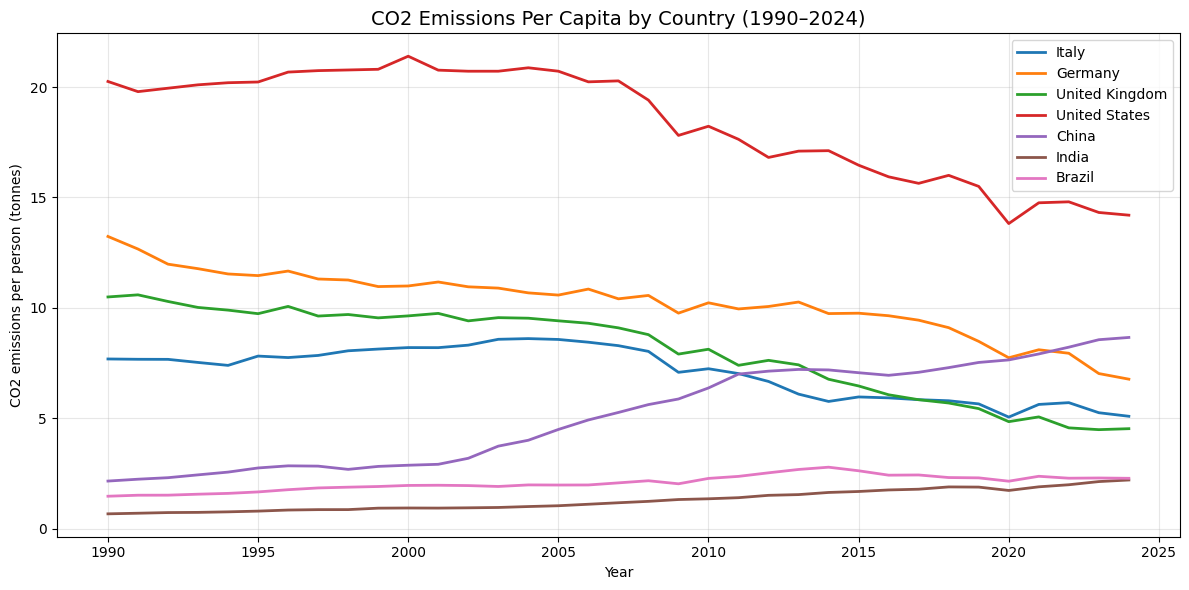

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for country in countries:
    country_data = df[
        df["country"] == country
    ].sort_values("year")

    plt.plot(
        country_data["year"],
        country_data["co2_per_capita"],
        label=country,
        linewidth=2
    )

plt.title(
    "CO2 Emissions Per Capita by Country (1990–2024)",
    fontsize=14
)

plt.xlabel("Year")
plt.ylabel("CO2 emissions per person (tonnes)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "co2_emissions_per_capita.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
energy_sources = [
    "coal_share_energy",
    "oil_share_energy",
    "gas_share_energy",
    "nuclear_share_energy",
    "renewables_share_energy"
]

for column in energy_sources:
    print(
        column,
        "->",
        column in df.columns
    )

coal_share_energy -> True
oil_share_energy -> True
gas_share_energy -> True
nuclear_share_energy -> True
renewables_share_energy -> True


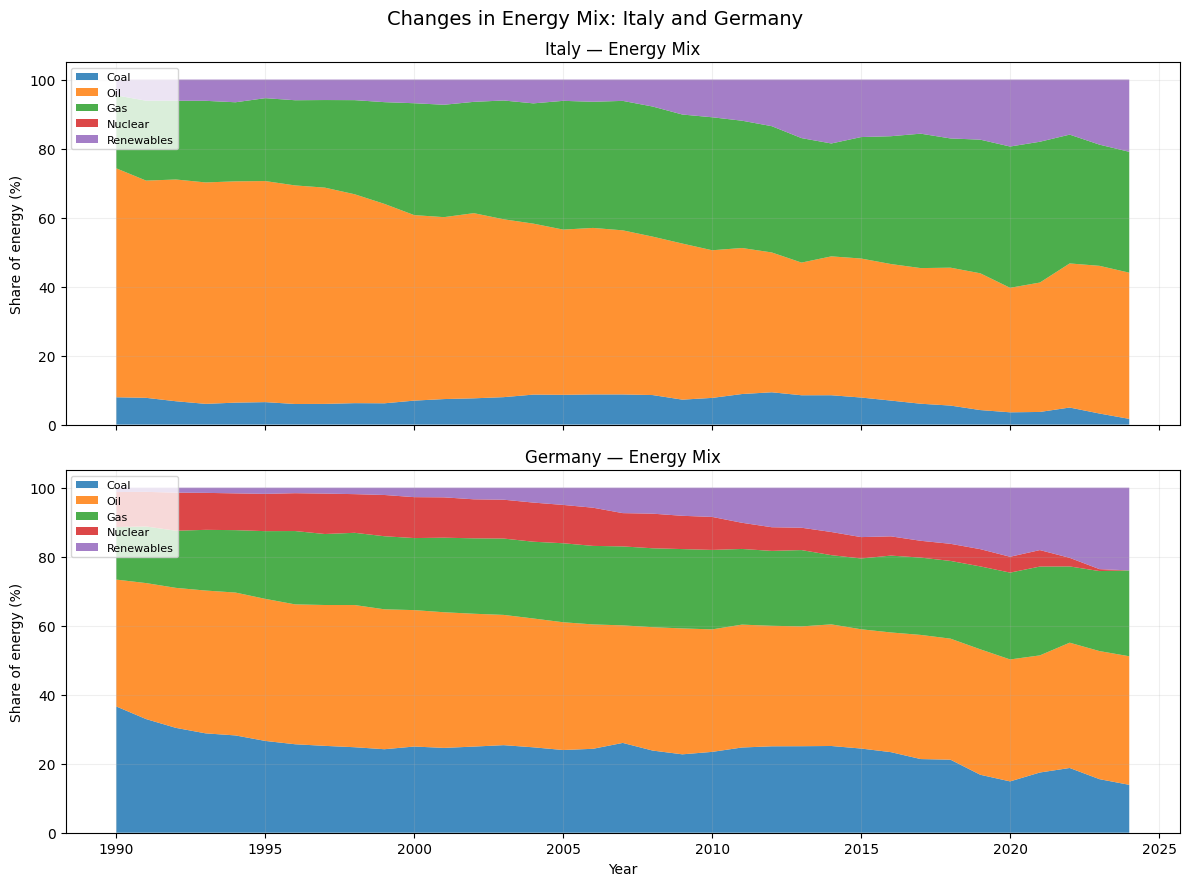

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 9),
    sharex=True
)

for ax, country in zip(
    axes,
    ["Italy", "Germany"]
):
    data = df[
        df["country"] == country
    ].sort_values("year").copy()

    data = data.dropna(
        subset=energy_sources
    )

    ax.stackplot(
        data["year"],
        *[data[col] for col in energy_sources],
        labels=[
            "Coal",
            "Oil",
            "Gas",
            "Nuclear",
            "Renewables"
        ],
        alpha=0.85
    )

    ax.set_title(country + " — Energy Mix")
    ax.set_ylabel("Share of energy (%)")
    ax.legend(loc="upper left", fontsize=8)
    ax.grid(True, alpha=0.2)

axes[-1].set_xlabel("Year")

plt.suptitle(
    "Changes in Energy Mix: Italy and Germany",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "energy_mix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
results = []

for country in countries:

    data = df[
        df["country"] == country
    ].sort_values("year")

    start = data[data["year"] == 1990]
    end = data[data["year"] == 2024]

    if start.empty or end.empty:
        print(country, "- missing baseline or final year")
        continue

    start = start.iloc[0]
    end = end.iloc[0]

    # Skip countries with invalid baseline values
    if (
        pd.isna(start["gdp"])
        or pd.isna(end["gdp"])
        or pd.isna(start["population"])
        or pd.isna(end["population"])
        or pd.isna(start["co2_per_capita"])
        or pd.isna(end["co2_per_capita"])
    ):
        print(country, "- missing required values")
        continue

    gdp_start_pc = start["gdp"] / start["population"]
    gdp_end_pc = end["gdp"] / end["population"]

    gdp_change = (
        gdp_end_pc / gdp_start_pc - 1
    ) * 100

    co2_change = (
        end["co2_per_capita"]
        / start["co2_per_capita"] - 1
    ) * 100

    results.append({
        "Country": country,
        "GDP per capita change (%)": round(gdp_change, 2),
        "CO2 per capita change (%)": round(co2_change, 2)
    })

summary = pd.DataFrame(results)

display(summary)

Italy - missing required values
Germany - missing required values
United Kingdom - missing required values
United States - missing required values
China - missing required values
India - missing required values
Brazil - missing required values


""


In [15]:
for country in countries:
    data = df[df["country"] == country].sort_values("year")

    print("\n", country)

    for year in [1990, 2024]:
        row = data[data["year"] == year]

        if row.empty:
            print(year, "- No matching row")
        else:
            row = row.iloc[0]

            print(
                year,
                "| GDP:", row["gdp"],
                "| Population:", row["population"],
                "| CO2 per capita:", row["co2_per_capita"]
            )
            


 Italy
1990 | GDP: 1475485283347.0 | Population: 57031457.0 | CO2 per capita: 7.683619976043701
2024 | GDP: nan | Population: 59342870.0 | CO2 per capita: 5.087885856628418

 Germany
1990 | GDP: 2015547498359.0 | Population: 79707963.0 | CO2 per capita: 13.233256340026855
2024 | GDP: nan | Population: 84552234.0 | CO2 per capita: 6.768823623657227

 United Kingdom
1990 | GDP: 1505692258761.0 | Population: 57367867.0 | CO2 per capita: 10.492722511291504
2024 | GDP: nan | Population: 69138185.0 | CO2 per capita: 4.52579927444458

 United States
1990 | GDP: 9250377579093.0 | Population: 253373387.0 | CO2 per capita: 20.253747940063477
2024 | GDP: nan | Population: 345426566.0 | CO2 per capita: 14.19728660583496

 China
1990 | GDP: 3385121670000.0 | Population: 1153582725.0 | CO2 per capita: 2.1528878211975098
2024 | GDP: nan | Population: 1419321284.0 | CO2 per capita: 8.658390045166016

 India
1990 | GDP: 1750993000000.0 | Population: 864972221.0 | CO2 per capita: 0.6682140231132507
202

In [16]:
results = []

for country in countries:
    data = df[df["country"] == country].copy()

    # Calculate GDP per capita
    data["gdp_per_capita"] = (
        data["gdp"] / data["population"]
    )

    # Keep valid, positive values for both indicators
    valid = data[
        data["year"].between(1990, 2024)
        & data["gdp_per_capita"].notna()
        & data["co2_per_capita"].notna()
        & data["gdp_per_capita"].gt(0)
        & data["co2_per_capita"].gt(0)
    ].sort_values("year")

    if len(valid) < 2:
        print(country, "- Not enough valid observations")
        continue

    start = valid.iloc[0]
    end = valid.iloc[-1]

    gdp_change = (
        end["gdp_per_capita"]
        / start["gdp_per_capita"] - 1
    ) * 100

    co2_change = (
        end["co2_per_capita"]
        / start["co2_per_capita"] - 1
    ) * 100

    results.append({
        "Country": country,
        "Start year": int(start["year"]),
        "End year": int(end["year"]),
        "GDP per capita change (%)": round(gdp_change, 2),
        "CO2 per capita change (%)": round(co2_change, 2)
    })

summary = pd.DataFrame(results)

display(summary)

,Country,Start year,End year,GDP per capita change (%),CO2 per capita change (%)
0,Italy,1990,2022,38.48,-25.75
1,Germany,1990,2022,83.87,-39.98
2,United Kingdom,1990,2022,46.15,-56.51
3,United States,1990,2022,56.33,-26.92
4,China,1990,2022,544.80,281.71
5,India,1990,2022,263.06,197.24
6,Brazil,1990,2022,90.68,55.70


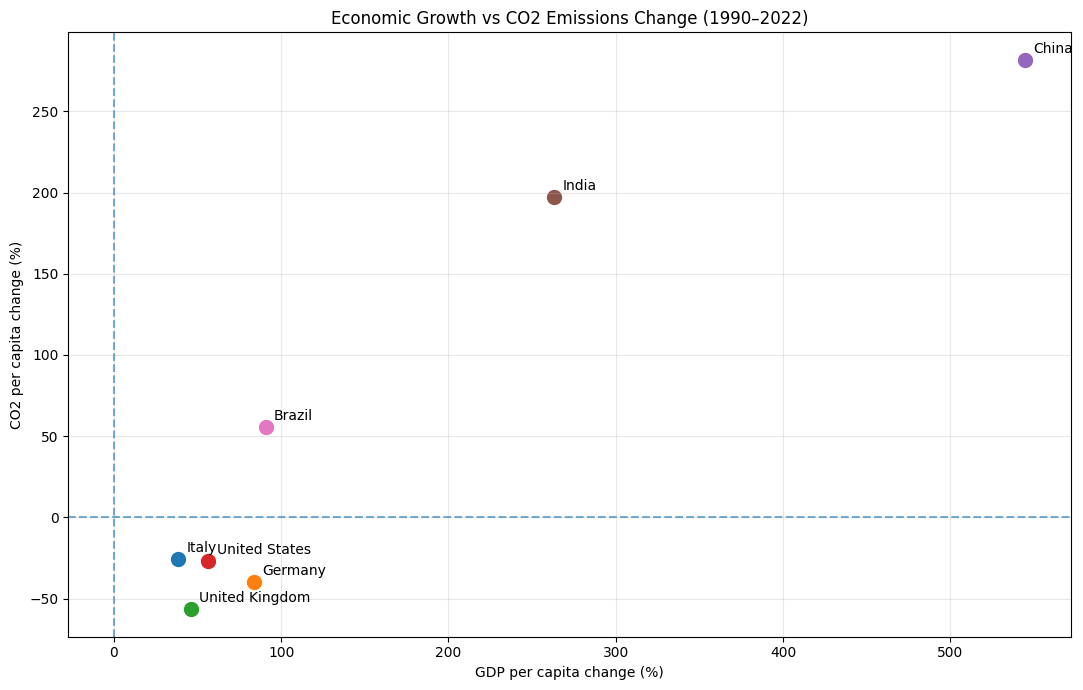

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7))

for _, row in summary.iterrows():
    plt.scatter(
        row["GDP per capita change (%)"],
        row["CO2 per capita change (%)"],
        s=100
    )

    plt.annotate(
        row["Country"],
        (
            row["GDP per capita change (%)"],
            row["CO2 per capita change (%)"]
        ),
        xytext=(6, 5),
        textcoords="offset points"
    )

# Reference lines for zero change
plt.axhline(0, linestyle="--", alpha=0.6)
plt.axvline(0, linestyle="--", alpha=0.6)

plt.title(
    "Economic Growth vs CO2 Emissions Change (1990–2022)"
)

plt.xlabel("GDP per capita change (%)")
plt.ylabel("CO2 per capita change (%)")

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "decoupling_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
summary["Finding"] = summary.apply(
    lambda row: (
        "Relative decoupling"
        if row["GDP per capita change (%)"] > 0
        and row["CO2 per capita change (%)"] < 0
        else "Growth with rising emissions"
        if row["GDP per capita change (%)"] > 0
        and row["CO2 per capita change (%)"] > 0
        else "Other trend"
    ),
    axis=1
)

display(summary)

,Country,Start year,End year,GDP per capita change (%),CO2 per capita change (%),Finding
0,Italy,1990,2022,38.48,-25.75,Relative decoupling
1,Germany,1990,2022,83.87,-39.98,Relative decoupling
2,United Kingdom,1990,2022,46.15,-56.51,Relative decoupling
3,United States,1990,2022,56.33,-26.92,Relative decoupling
4,China,1990,2022,544.80,281.71,Growth with rising emissions
5,India,1990,2022,263.06,197.24,Growth with rising emissions
6,Brazil,1990,2022,90.68,55.70,Growth with rising emissions


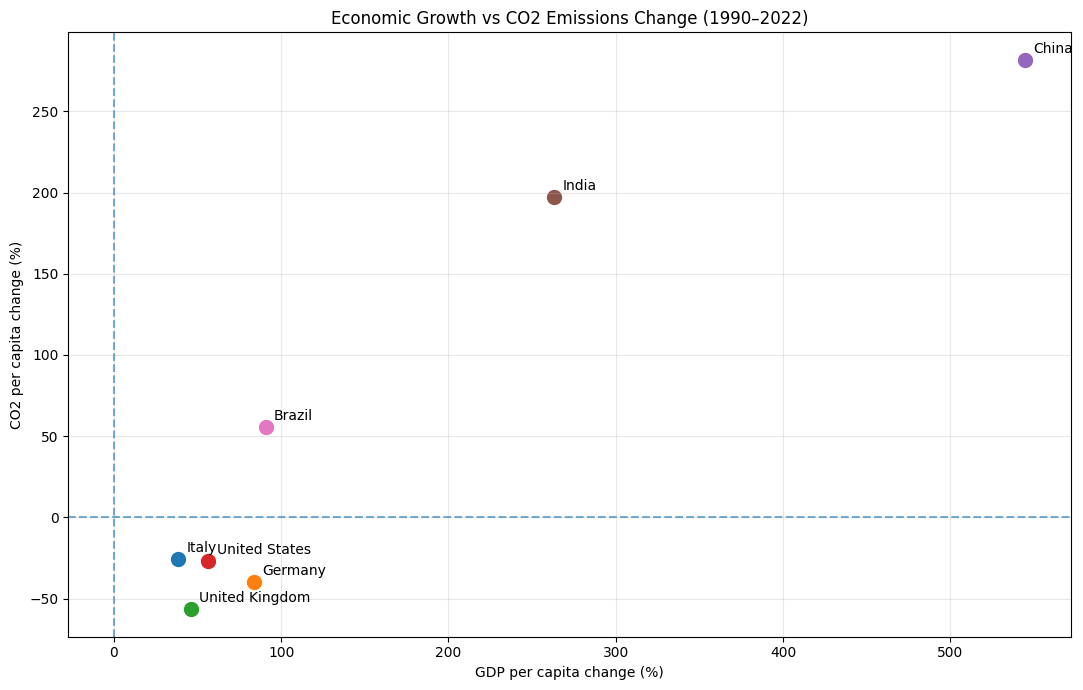

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7))

for _, row in summary.iterrows():
    plt.scatter(
        row["GDP per capita change (%)"],
        row["CO2 per capita change (%)"],
        s=100
    )

    plt.annotate(
        row["Country"],
        (
            row["GDP per capita change (%)"],
            row["CO2 per capita change (%)"]
        ),
        xytext=(6, 5),
        textcoords="offset points"
    )

plt.axhline(0, linestyle="--", alpha=0.6)
plt.axvline(0, linestyle="--", alpha=0.6)

plt.title("Economic Growth vs CO2 Emissions Change (1990–2022)")
plt.xlabel("GDP per capita change (%)")
plt.ylabel("CO2 per capita change (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("decoupling_chart.png", dpi=300, bbox_inches="tight")
plt.show()

In [20]:
energy_sources = [
    "coal_share_energy",
    "oil_share_energy",
    "gas_share_energy",
    "nuclear_share_energy",
    "renewables_share_energy"
]

print({
    col: col in energy.columns
    for col in energy_sources
})

{'coal_share_energy': True, 'oil_share_energy': True, 'gas_share_energy': True, 'nuclear_share_energy': True, 'renewables_share_energy': True}


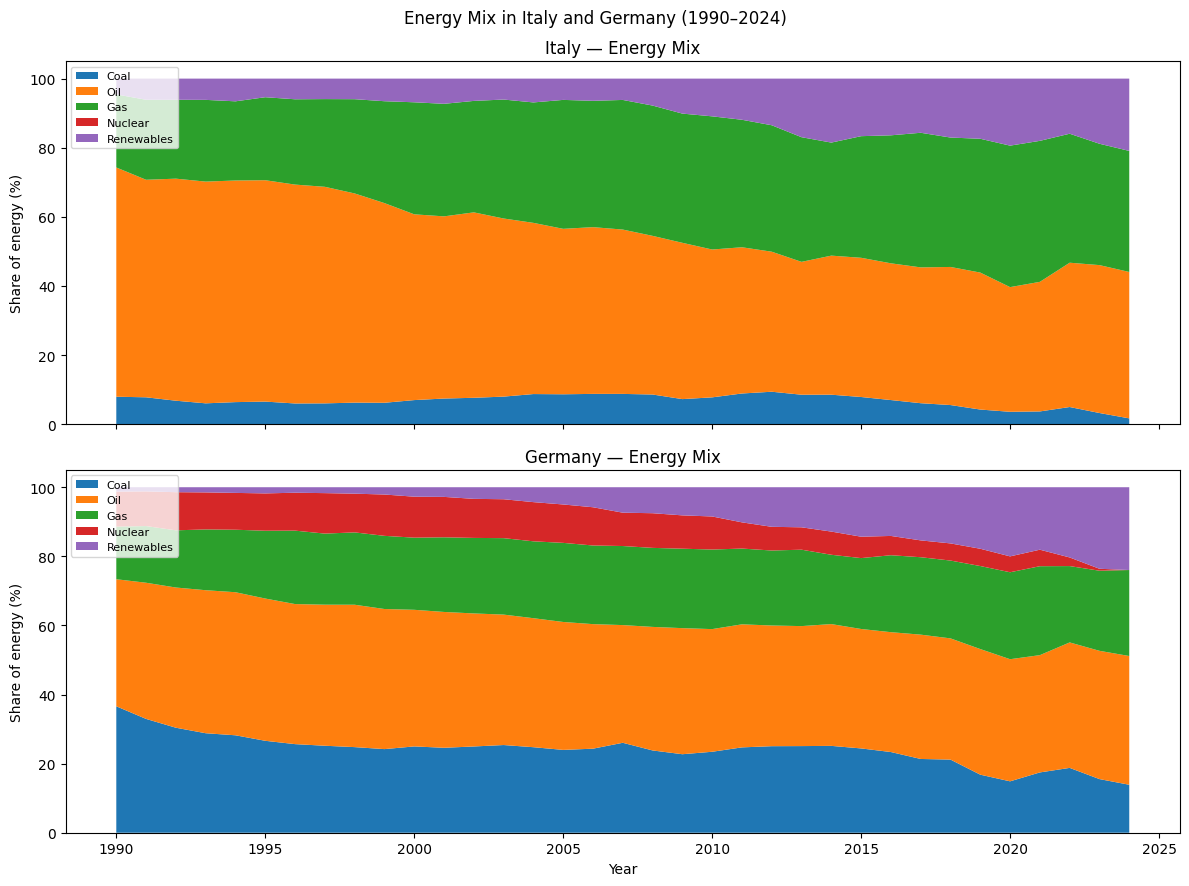

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

for ax, country in zip(axes, ["Italy", "Germany"]):
    data = energy_clean[
        energy_clean["country"] == country
    ].sort_values("year").copy()

    data = data[data["year"] <= 2024]
    data = data.dropna(subset=energy_sources)

    ax.stackplot(
        data["year"],
        *[data[col] for col in energy_sources],
        labels=["Coal", "Oil", "Gas", "Nuclear", "Renewables"]
    )

    ax.set_title(country + " — Energy Mix")
    ax.set_ylabel("Share of energy (%)")
    ax.legend(loc="upper left", fontsize=8)

axes[-1].set_xlabel("Year")
plt.suptitle("Energy Mix in Italy and Germany (1990–2024)")
plt.tight_layout()
plt.savefig("energy_mix.png", dpi=300, bbox_inches="tight")
plt.show()

In [22]:
summary.to_csv("decoupling_results.csv", index=False)

print("Results exported successfully!")

Results exported successfully!


In [23]:
energy_sources = [
    "coal_share_energy",
    "oil_share_energy",
    "gas_share_energy",
    "nuclear_share_energy",
    "renewables_share_energy"
]

for country in ["Italy", "Germany"]:
    data = energy_clean[
        (energy_clean["country"] == country)
        & (energy_clean["year"].between(1990, 2024))
    ].copy()

    data["total_selected_share"] = data[
        energy_sources
    ].sum(axis=1, min_count=5)

    print("\n", country)
    display(
        data.loc[
            data["year"].isin([1990, 2000, 2010, 2020, 2024]),
            ["year", *energy_sources, "total_selected_share"]
        ].round(2)
    )


 Italy


,year,coal_share_energy,oil_share_energy,gas_share_energy,nuclear_share_energy,renewables_share_energy,total_selected_share
10418,1990,7.93,66.35,21.15,0.0,4.57,100.0
10428,2000,6.95,53.77,32.43,0.0,6.85,100.0
10438,2010,7.74,42.79,38.54,0.0,10.92,100.0
10448,2020,3.56,36.09,40.95,0.0,19.40,100.0
10452,2024,1.66,42.37,35.03,0.0,20.93,100.0



 Germany


,year,coal_share_energy,oil_share_energy,gas_share_energy,nuclear_share_energy,renewables_share_energy,total_selected_share
8247,1990,36.59,36.77,15.24,10.13,1.26,100.0
8257,2000,24.98,39.54,20.88,11.86,2.74,100.0
8267,2010,23.43,35.50,23.03,9.57,8.47,100.0
8277,2020,14.88,35.34,25.17,4.59,20.02,100.0
8281,2024,13.88,37.27,24.89,0.00,23.97,100.0
